In [7]:
# packages
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
from matplotlib.pyplot import subplots
import statsmodels.api as sm
from sklearn.model_selection import train_test_split 
from sklearn.tree import \
      (DecisionTreeRegressor as DTR, 
       DecisionTreeClassifier as DTC, 
       plot_tree)
from sklearn.ensemble import \
     (RandomForestRegressor as RFR,
      RandomForestClassifier as RFC,
      GradientBoostingRegressor as GBR)
from sklearn.model_selection import cross_val_score

# set seed
seed = 5498

### You'll need the heart attack data (heart.csv) to complete this exercise. Your goal is to predict the risk of having a heart attack (binary).

In [8]:
heart = pd.read_csv('data/heart.csv')
heart.head()

,Patient ID,Age,Sex,Cholesterol,Blood Pressure,Heart Rate,Diabetes,Family History,Smoking,Obesity,...,Sedentary Hours Per Day,Income,BMI,Triglycerides,Physical Activity Days Per Week,Sleep Hours Per Day,Country,Continent,Hemisphere,Heart Attack Risk
0,UEX5427,40,Male,122,144/90,110,1,0,1,1,...,1.538008,252889,28.854477,318,6,7,Thailand,Asia,Northern Hemisphere,1
1,NBG3103,41,Male,357,174/73,109,0,1,1,1,...,7.030873,63196,37.387161,72,7,9,France,Europe,Northern Hemisphere,1
2,EIE1041,58,Male,206,107/105,63,0,0,1,0,...,8.086554,107870,20.299119,119,2,5,Colombia,South America,Northern Hemisphere,0
3,GYA0389,30,Male,142,132/107,86,1,0,1,0,...,5.039048,223985,30.717640,301,5,9,South Africa,Africa,Southern Hemisphere,0
4,IXT9616,69,Male,175,153/93,98,1,1,1,1,...,4.354972,24309,19.115698,675,7,7,Japan,Asia,Northern Hemisphere,0


In [9]:
heart.dtypes

Patient ID                          object
Age                                  int64
Sex                                 object
Cholesterol                          int64
Blood Pressure                      object
Heart Rate                           int64
Diabetes                             int64
Family History                       int64
Smoking                              int64
Obesity                              int64
Alcohol Consumption                  int64
Exercise Hours Per Week            float64
Diet                                object
Previous Heart Problems              int64
Medication Use                       int64
Stress Level                         int64
Sedentary Hours Per Day            float64
Income                               int64
BMI                                float64
Triglycerides                        int64
Physical Activity Days Per Week      int64
Sleep Hours Per Day                  int64
Country                             object
Continent  

In [10]:
heart.shape

(6572, 26)

### Feature engineering

In [11]:
def feature_engineering(df=heart):
    df['Male'] = (df.Sex == 'Male').astype(int)
    df['HealthyDiet'] = (df.Diet == 'Healthy').astype(int)
    df['UnhealthyDiet'] = (df.Diet == 'Unhealthy').astype(int)
    df[['BP1','BP2']] = df['Blood Pressure'].str.split('/', n=1, expand=True).astype(int)

feature_engineering()

In [12]:
heart.head()

,Patient ID,Age,Sex,Cholesterol,Blood Pressure,Heart Rate,Diabetes,Family History,Smoking,Obesity,...,Sleep Hours Per Day,Country,Continent,Hemisphere,Heart Attack Risk,Male,HealthyDiet,UnhealthyDiet,BP1,BP2
0,UEX5427,40,Male,122,144/90,110,1,0,1,1,...,7,Thailand,Asia,Northern Hemisphere,1,1,0,0,144,90
1,NBG3103,41,Male,357,174/73,109,0,1,1,1,...,9,France,Europe,Northern Hemisphere,1,1,1,0,174,73
2,EIE1041,58,Male,206,107/105,63,0,0,1,0,...,5,Colombia,South America,Northern Hemisphere,0,1,0,0,107,105
3,GYA0389,30,Male,142,132/107,86,1,0,1,0,...,9,South Africa,Africa,Southern Hemisphere,0,1,0,1,132,107
4,IXT9616,69,Male,175,153/93,98,1,1,1,1,...,7,Japan,Asia,Northern Hemisphere,0,1,0,1,153,93


In [13]:
indep_vars = ['Age', 'Male', 'Cholesterol', 'BP1', 'BP2', 'Heart Rate', 'Diabetes', 
              'Family History', 'Smoking', 'Obesity', 'Alcohol Consumption', 'HealthyDiet', 
              'UnhealthyDiet', 'Exercise Hours Per Week', 'Previous Heart Problems', 
              'Medication Use', 'Stress Level', 'Sedentary Hours Per Day', 'Income', 'BMI',
              'Triglycerides', 'Physical Activity Days Per Week', 'Sleep Hours Per Day']

X = heart[indep_vars]
y = heart['Heart Attack Risk']

In [14]:
X_train, X_test, y_train, y_test, Train, Test = train_test_split(X, y, heart, 
                                                                 random_state = seed, 
                                                                 test_size = 0.33, 
                                                                 shuffle = True)

### Univariate Analyses (Mean, Median, etc.)

In [15]:
Train.describe()

,Age,Cholesterol,Heart Rate,Diabetes,Family History,Smoking,Obesity,Alcohol Consumption,Exercise Hours Per Week,Previous Heart Problems,...,BMI,Triglycerides,Physical Activity Days Per Week,Sleep Hours Per Day,Heart Attack Risk,Male,HealthyDiet,UnhealthyDiet,BP1,BP2
count,4403.000000,4403.000000,4403.000000,4403.000000,4403.000000,4403.000000,4403.000000,4403.000000,4403.000000,4403.000000,...,4403.000000,4403.000000,4403.000000,4403.000000,4403.000000,4403.000000,4403.000000,4403.000000,4403.000000,4403.000000
mean,53.760164,261.571201,75.398592,0.656371,0.487168,0.895526,0.503066,0.599364,10.123129,0.506246,...,28.876482,418.384738,3.470815,7.045651,0.363389,0.703157,0.336589,0.334999,135.339768,85.200318
std,21.302684,81.111506,20.455754,0.474973,0.499892,0.305909,0.500047,0.490083,5.814093,0.500018,...,6.266748,222.756253,2.289825,1.986313,0.481030,0.456919,0.472597,0.472044,26.471761,14.656039
min,18.000000,120.000000,40.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.004443,0.000000,...,18.009025,30.000000,0.000000,4.000000,0.000000,0.000000,0.000000,0.000000,90.000000,60.000000
25%,35.000000,194.000000,58.000000,0.000000,0.000000,1.000000,0.000000,0.000000,5.081525,0.000000,...,23.397345,229.000000,1.000000,5.000000,0.000000,0.000000,0.000000,0.000000,112.500000,72.000000
50%,54.000000,261.000000,75.000000,1.000000,0.000000,1.000000,1.000000,1.000000,10.266242,1.000000,...,28.768101,419.000000,3.000000,7.000000,0.000000,1.000000,0.000000,0.000000,135.000000,85.000000
75%,72.000000,333.000000,93.000000,1.000000,1.000000,1.000000,1.000000,1.000000,15.292125,1.000000,...,34.269966,608.000000,5.000000,9.000000,1.000000,1.000000,1.000000,1.000000,159.000000,98.000000
max,90.000000,400.000000,110.000000,1.000000,1.000000,1.000000,1.000000,1.000000,19.998709,1.000000,...,39.997211,800.000000,7.000000,10.000000,1.000000,1.000000,1.000000,1.000000,180.000000,110.000000


### Correlation Matrix

In [16]:
X_train.corr().style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1)

,Age,Male,Cholesterol,BP1,BP2,Heart Rate,Diabetes,Family History,Smoking,Obesity,Alcohol Consumption,HealthyDiet,UnhealthyDiet,Exercise Hours Per Week,Previous Heart Problems,Medication Use,Stress Level,Sedentary Hours Per Day,Income,BMI,Triglycerides,Physical Activity Days Per Week,Sleep Hours Per Day
Age,1.000000,0.027272,-0.009153,0.008641,-0.002659,-0.003114,-0.017869,0.017139,0.398364,-0.008461,0.001217,-0.007662,0.010590,0.010047,-0.009670,0.006967,0.013658,0.024350,0.005220,-0.010506,0.014587,-0.009942,-0.016148
Male,0.027272,1.000000,0.016676,-0.006140,0.001995,-0.000366,0.000917,-0.000270,0.525688,0.000504,0.005447,0.006229,-0.004378,-0.009530,-0.011272,0.006828,-0.039140,-0.010779,0.007646,0.010282,0.015317,0.003985,-0.007092
Cholesterol,-0.009153,0.016676,1.000000,0.005745,-0.017203,-0.012507,-0.028839,-0.032771,0.026621,-0.015891,-0.022353,0.004833,-0.014249,0.016741,-0.022367,-0.001884,-0.034351,0.027106,-0.001468,0.012924,-0.014398,0.029993,-0.002332
BP1,0.008641,-0.006140,0.005745,1.000000,0.010701,0.022688,-0.012339,-0.015910,0.001102,0.000024,0.000444,-0.010324,-0.003148,0.003553,-0.022952,-0.000809,0.016166,0.016528,-0.002618,0.020022,0.014007,-0.017409,0.008220
BP2,-0.002659,0.001995,-0.017203,0.010701,1.000000,-0.011255,-0.007699,0.041776,-0.031407,-0.010003,-0.010521,0.014009,-0.005860,-0.014261,-0.003488,0.004126,0.002516,-0.007814,0.022487,0.007131,0.008308,0.001704,0.013755
Heart Rate,-0.003114,-0.000366,-0.012507,0.022688,-0.011255,1.000000,0.013984,-0.021304,-0.010406,0.017814,-0.000881,-0.017735,-0.020490,-0.003555,-0.023864,0.003857,-0.004242,-0.037228,0.017454,-0.017648,-0.003075,0.016770,0.016767
Diabetes,-0.017869,0.000917,-0.028839,-0.012339,-0.007699,0.013984,1.000000,-0.017140,-0.006363,0.021175,0.012529,0.014430,-0.026492,-0.006420,0.006648,0.013017,0.001319,0.004841,0.009121,-0.015689,0.006697,0.013022,0.004351
Family History,0.017139,-0.000270,-0.032771,-0.015910,0.041776,-0.021304,-0.017140,1.000000,0.000144,-0.002796,0.000338,-0.001907,0.015815,-0.021142,-0.003542,-0.010742,0.015665,0.009992,0.008011,-0.023486,-0.016172,0.009348,-0.016454
Smoking,0.398364,0.525688,0.026621,0.001102,-0.031407,-0.010406,-0.006363,0.000144,1.000000,0.009520,0.016225,-0.000266,-0.007709,-0.006519,-0.018010,-0.002338,-0.022788,0.014017,0.007357,0.011295,0.033460,0.000835,-0.023927
Obesity,-0.008461,0.000504,-0.015891,0.000024,-0.010003,0.017814,0.021175,-0.002796,0.009520,1.000000,-0.035773,0.000438,-0.010608,0.012616,0.032404,-0.004300,-0.005804,0.000109,-0.003053,-0.011320,0.015713,0.016892,0.001803


### To predict heart attack risk, we'll start by building a few simple decision trees.

In [17]:
tree1 = DTC(max_depth=1)
tree1.fit(X_train, y_train)

tree2 = DTC(max_depth=2)
tree2.fit(X_train, y_train)

tree3 = DTC(max_depth=3)
tree3.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


### We can draw plots of each of these decision trees

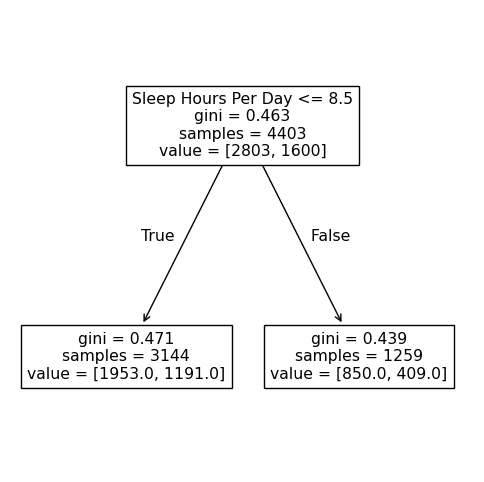

In [18]:
feature_names = list(X_train.columns)
ax = subplots(figsize=(6,6))[1]
plot_tree(tree1,
          feature_names=feature_names,
          ax=ax);

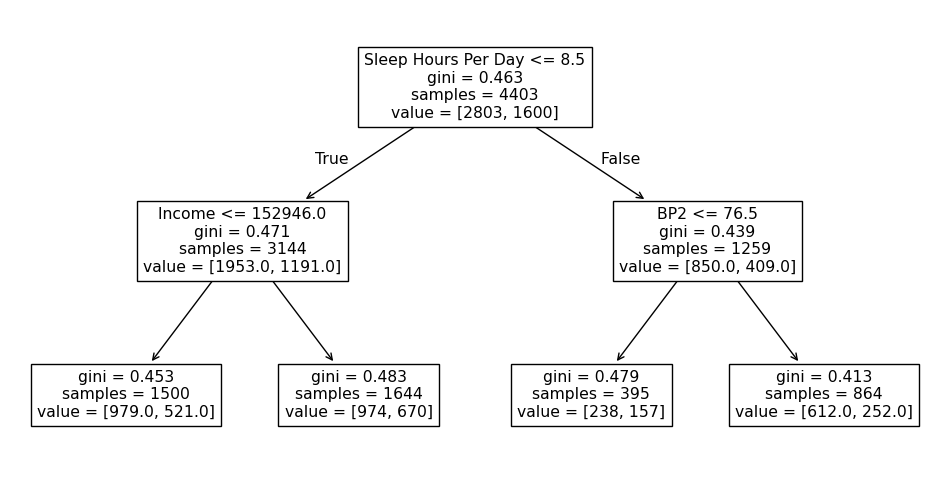

In [19]:
ax = subplots(figsize=(12,6))[1]
plot_tree(tree2,
          feature_names=feature_names,
          ax=ax);

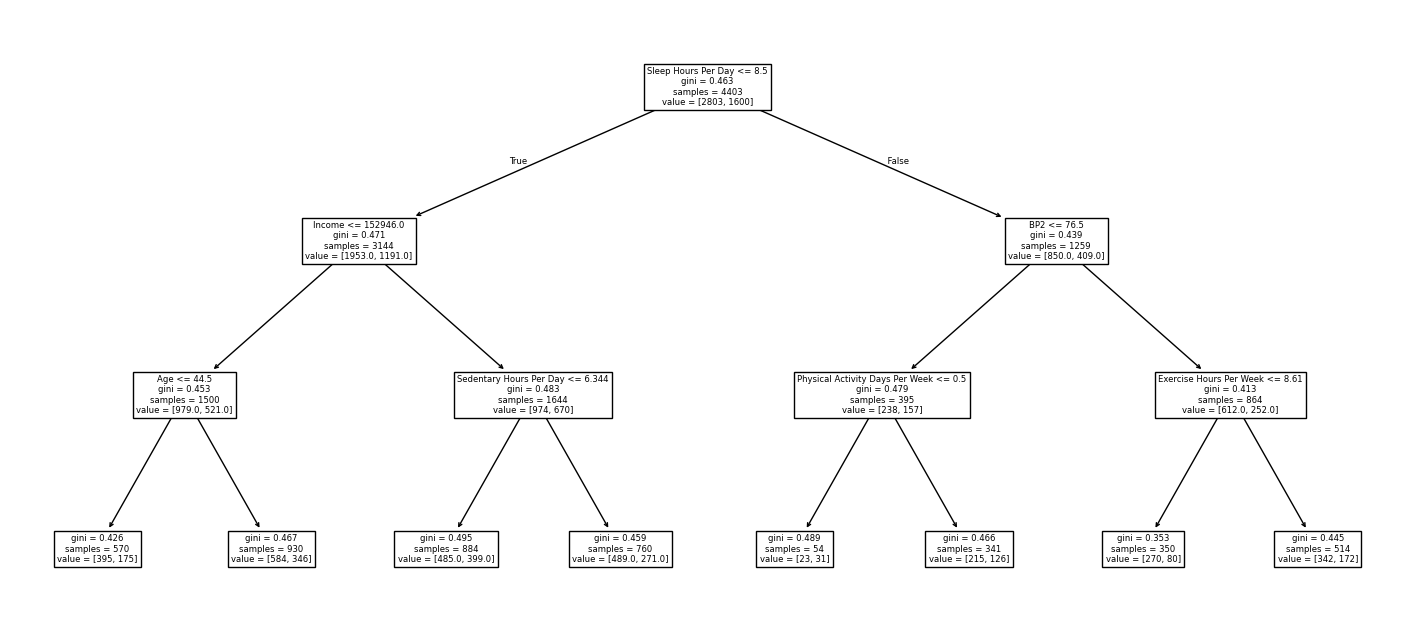

In [20]:
ax = subplots(figsize=(18,8))[1]
plot_tree(tree3,
          feature_names=feature_names,
          ax=ax);

### Create a new tree with depth 3 that requires there to be at least 100 records in each leaf.

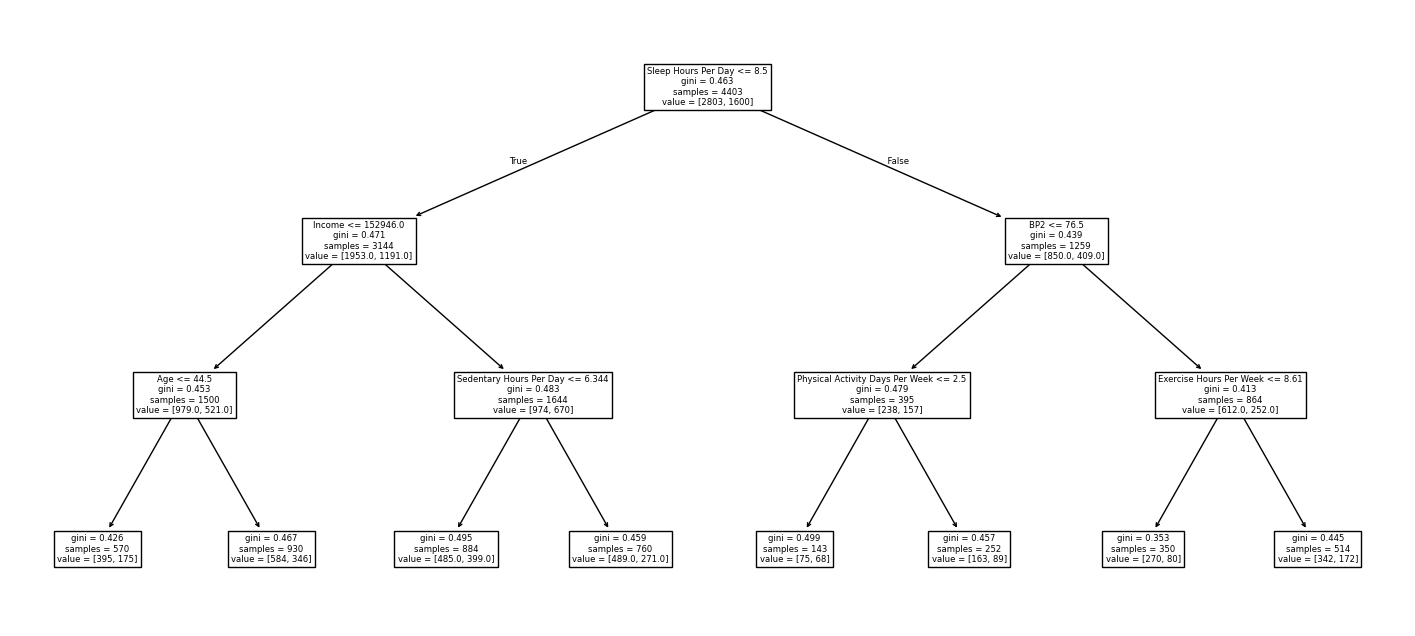

In [21]:
tree4 = DTC(max_depth=3, min_samples_leaf=100)
tree4.fit(X_train, y_train)

ax = subplots(figsize=(18,8))[1]
plot_tree(tree4,
          feature_names=feature_names,
          ax=ax);

### Create a new version of the last tree so that it limits the number of leaf nodes to 8 rather than limiting the depth to 3.

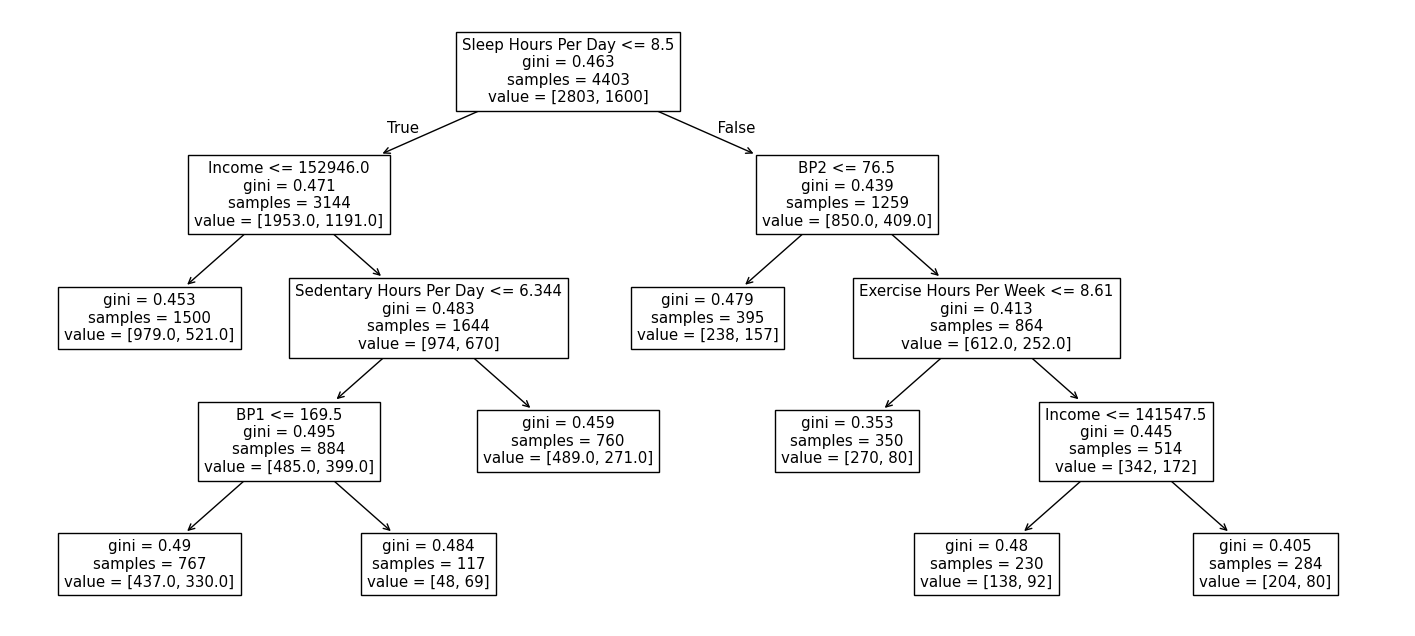

In [22]:
tree5 = DTC(max_leaf_nodes=8, min_samples_leaf=100)
tree5.fit(X_train, y_train)

ax = subplots(figsize=(18,8))[1]
plot_tree(tree5,
          feature_names=feature_names,
          ax=ax);

### Create a basic random forest model on the training set.

In [23]:
rf_basic = RFC(max_features=len(indep_vars),
               criterion='log_loss',
               n_estimators=50,
               max_depth=10,
               min_samples_leaf=1,
               bootstrap=True,
               oob_score=True,
               random_state=seed)
rf_basic.fit(X_train, y_train)

,n_estimators,50
,criterion,'log_loss'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,23
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,True


### We'll use this function to quickly calculate the log loss of a model.

In [24]:
def log_loss(y_true, y_prob, eps=1e-15):
    y_true = np.array(y_true)
    y_prob = np.array(y_prob)
    
    # avoid log(0)
    y_prob = np.clip(y_prob, eps, 1 - eps)
    
    ll = -np.mean(y_true * np.log(y_prob) + (1 - y_true) * np.log(1 - y_prob))
    return ll

### Compute the log loss on the training set.

In [25]:
y_hat_basic_train = rf_basic.predict_proba(X_train)[:,1]
print('train log loss:', log_loss(y_train, y_hat_basic_train))

train log loss: 0.4682493561945568


### Calculate the out-of-bag error (bootstrapping) on training data to estimate the log loss on the test set.

In [26]:
y_hat_basic_oob = rf_basic.oob_decision_function_[:,1]
print('oob log loss:  ', log_loss(y_train, y_hat_basic_oob))

oob log loss:   0.6662770624624337


### Compute the log loss on the test set.

In [27]:
y_hat_basic_test = rf_basic.predict_proba(X_test)[:,1]
print('test log loss: ', log_loss(y_test, y_hat_basic_test))

test log loss:  0.65752143530385


### Build an improved random forest model on this same set of data. 

You will be scored according to how well it performs on an unseen holdout set.

In [28]:
# Documentation: https://scikit-learn.org/dev/modules/generated/sklearn.ensemble.RandomForestRegressor.html

rf_better = RFC(max_features='sqrt',
                criterion='log_loss',
                n_estimators=500,
                max_depth=6,
                min_samples_leaf=50,
                bootstrap=True,
                oob_score=True,
                random_state=seed,
                n_jobs=-1)
rf_better.fit(X_train, y_train)

,n_estimators,500
,criterion,'log_loss'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,50
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,True


### Calculate the out-of-bag log loss for this model. Store it as `log_loss_oob`

In [29]:
y_hat_better_oob = rf_better.oob_decision_function_[:,1]

log_loss_oob = log_loss(y_train, y_hat_better_oob)
print(log_loss_oob)

0.6546412461706448


### Create the feature importance list for this model.

In [30]:
feature_imp = pd.DataFrame(
    {'importance':rf_better.feature_importances_},
    index=indep_vars)
feature_imp

,importance
Age,0.066591
Male,0.008184
Cholesterol,0.070645
BP1,0.069954
BP2,0.064190
Heart Rate,0.060040
Diabetes,0.008392
Family History,0.007606
Smoking,0.002366
Obesity,0.011024


### Sort the importance values and then create a horizontal bar chart that displays the sorted variable importances.

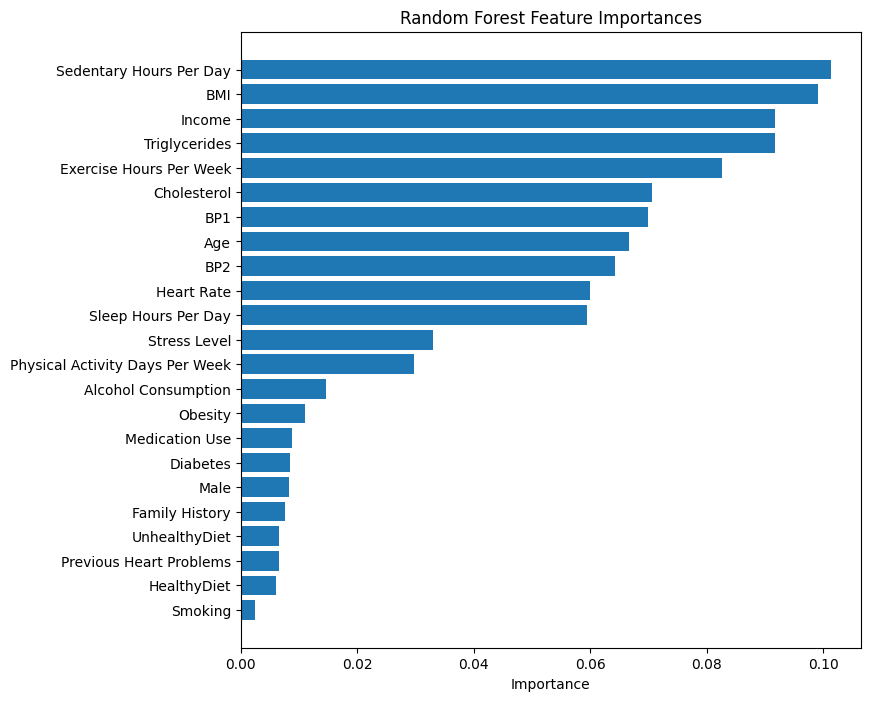

In [31]:
feature_imp_sorted = feature_imp.sort_values('importance', ascending=True)

# Draw a horizontal bar chart
ax = subplots(figsize=(8,8))[1]
ax.barh(feature_imp_sorted.index, feature_imp_sorted['importance'])
ax.set_xlabel('Importance')
ax.set_title('Random Forest Feature Importances');

## Discussion Questions

### (1) Explain what "value" means in the decision tree plots.

"value" shows how the training records that reach a node are split across the two classes of `Heart Attack Risk`, written as `[class 0, class 1]`. Older versions of scikit-learn show counts (for example `[3600, 2270]`). Version 1.4 and later show proportions (for example `[0.61, 0.39]`). The values in each node add up to its `samples` count, or to 1 when shown as proportions. The tree predicts the larger class in a leaf, and the class-1 share is the predicted probability of heart attack risk. Splits are chosen to make these values as uneven as possible, which means the leaves are purer.

### (2) How is “log loss” different from the log likelihood we defined in class?

They measure the same thing with a different sign and scale. The log likelihood from class adds up the log of the probability the model gives to each observed outcome:

$$\ell = \sum_{i=1}^{n} \left[ y_i \log(p_i) + (1-y_i)\log(1-p_i) \right]$$

We **maximize** it, and it is always ≤ 0. Log loss is the **negative average** of the same quantity:

$$\text{log loss} = -\frac{1}{n}\sum_{i=1}^{n} \left[ y_i \log(p_i) + (1-y_i)\log(1-p_i) \right] = -\frac{\ell}{n}$$

So log loss is something we **minimize**, and it is always ≥ 0 (0 means perfect predictions). Dividing by $n$ means it doesn't grow with the size of the dataset, so we can compare it across the train, OOB and test sets even though they have different numbers of rows. Our `log_loss` function also clips the probabilities away from 0 and 1 so that $\log(0)$ never makes it infinite.

### (3) Explain how we know the basic model is overfit before attempting to build any other models.

The training log loss is much lower than the out-of-bag log loss. The OOB estimate comes from training data only. Each tree is scored on the bootstrap records it never saw, so the OOB log loss estimates performance on new data without touching the test set. When a model does far better on the data it was trained on than on data it hasn't seen, it has memorized noise rather than learned general patterns, which is overfitting.

The settings explain why:
- `max_depth=10` and `min_samples_leaf=1` let each tree grow very deep, down to leaves with a single record, so each tree can fit individual training points.
- `max_features=len(indep_vars)` lets every split consider every variable. That makes this bagging rather than a true random forest: the trees are highly correlated, so averaging them removes less variance.
- `n_estimators=50` is a fairly small number of trees to average over.

Very confident probabilities (close to 0 or 1) on training data that turn out wrong on unseen data are punished heavily by log loss. That is why the OOB (and test) log loss is so much higher than the training log loss.